In [1]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

COUNTRY = "Zambia"   # "India" or "Zambia"

df = pd.read_csv(f"clean_monthly_{COUNTRY.lower()}.csv", parse_dates=["date"])
df = df.sort_values(["commodity", "date"]).reset_index(drop=True)
currency = df["currency"].iloc[0]
coms = df["commodity"].unique()

assert df["price"].notna().all(), "Fill or handle remaining gaps in notebook 1 first"
df.head()

,date,commodity,price,n_markets,was_filled,country,currency
0,2012-02-01,Beans (dry),10.983000,31,False,Zambia,ZMW
1,2012-03-01,Beans (dry),10.658000,33,False,Zambia,ZMW
2,2012-04-01,Beans (dry),9.683750,62,False,Zambia,ZMW
3,2012-05-01,Beans (dry),9.986237,62,False,Zambia,ZMW
4,2012-06-01,Beans (dry),9.719067,62,False,Zambia,ZMW


In [11]:
summary = df.groupby("commodity")["price"].agg(
    months="size", mean="mean", std="std", min="min", max="max"
)
summary["cv"] = summary["std"] / summary["mean"]   # relative variability
summary.round(2)

,months,mean,std,min,max,cv
commodity,,,,,,
Beans (dry),101,14.36,3.13,9.68,20.00,0.22
Groundnuts (shelled),100,14.93,3.46,9.53,21.48,0.23
Maize (white),210,1.43,0.78,0.46,4.94,0.55
"Maize meal (white, roller)",98,2.66,1.07,1.07,5.95,0.40


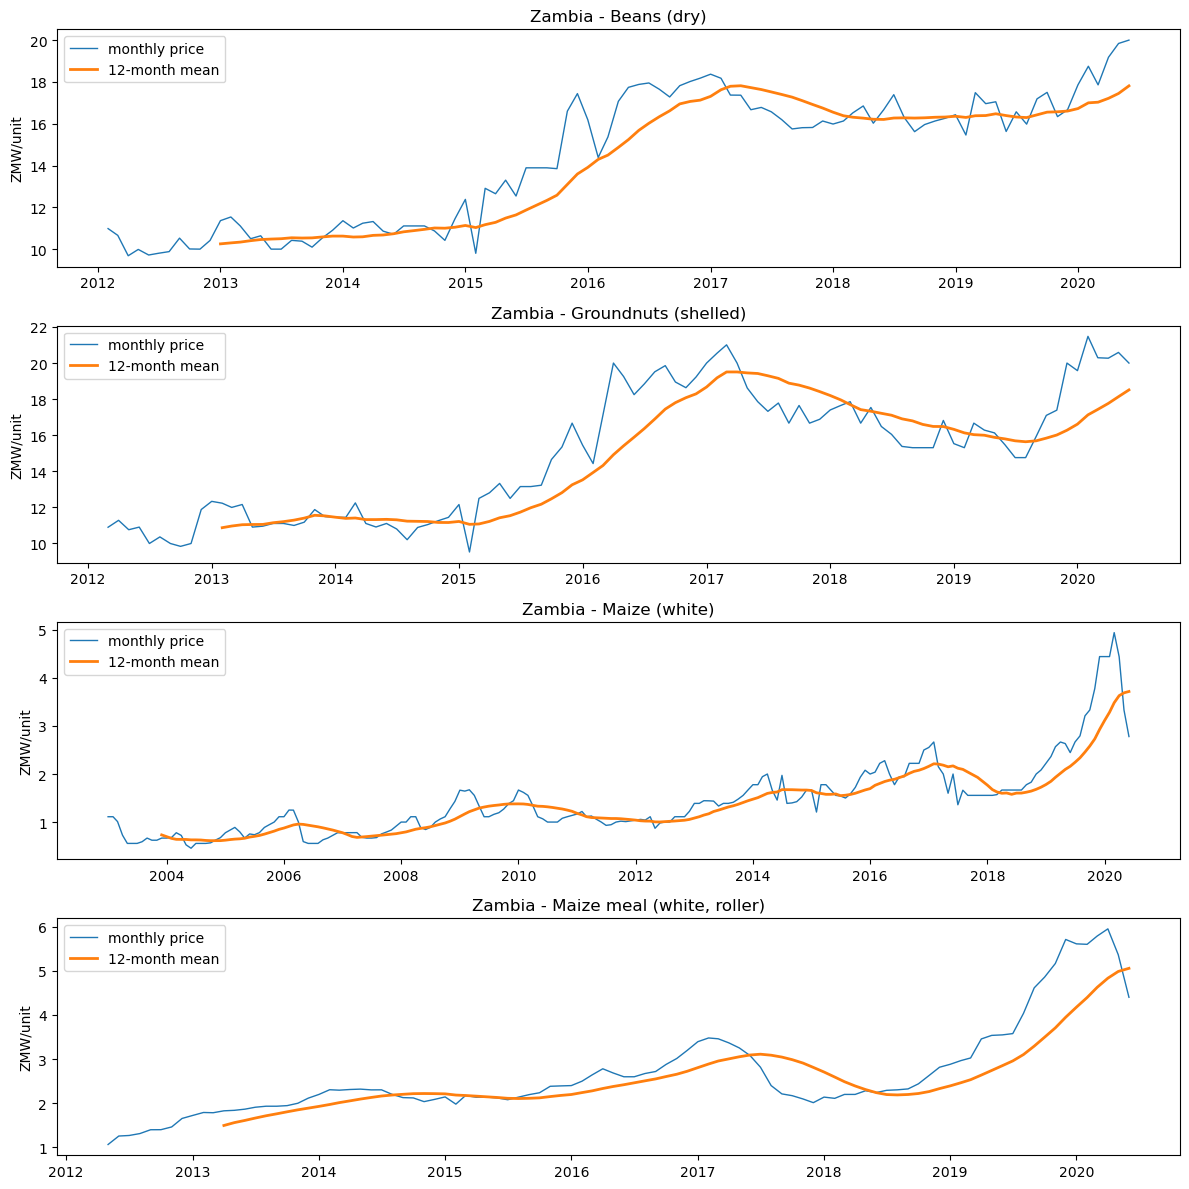

In [12]:
fig, axes = plt.subplots(len(coms), 1, figsize=(12, 3 * len(coms)))
axes = np.atleast_1d(axes)

for ax, com in zip(axes, coms):
    s = df[df["commodity"] == com].set_index("date")["price"]
    ax.plot(s, lw=1, label="monthly price")
    ax.plot(s.rolling(12).mean(), lw=2, label="12-month mean")
    ax.set_title(f"{COUNTRY} - {com}")
    ax.set_ylabel(f"{currency}/unit")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

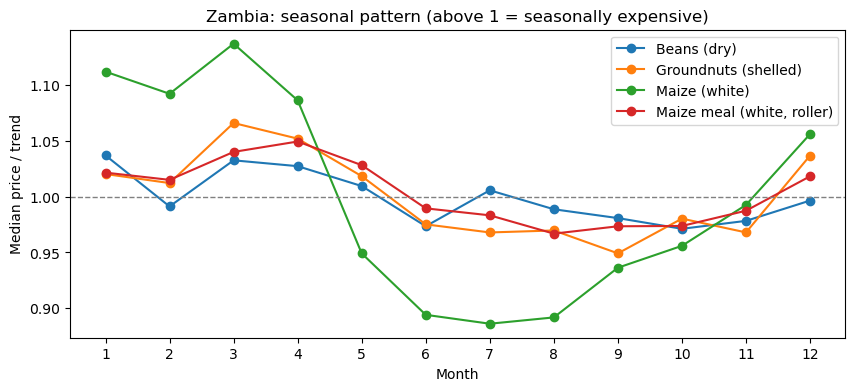

In [13]:
rows = []
for com in coms:
    s = df[df["commodity"] == com].set_index("date")["price"]
    trend = s.rolling(12, center=True).mean()
    idx = (s / trend).dropna()
    rows.append(idx.groupby(idx.index.month).median().rename(com))

seasonal = pd.concat(rows, axis=1)

ax = seasonal.plot(marker="o", figsize=(10, 4))
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Median price / trend")
ax.set_title(f"{COUNTRY}: seasonal pattern (above 1 = seasonally expensive)")
plt.show()

                             mean    std   skew    max    min
commodity                                                    
Beans (dry)                 0.008  0.062  1.140  0.317 -0.208
Groundnuts (shelled)        0.008  0.068  1.006  0.312 -0.216
Maize (white)               0.011  0.109 -0.432  0.471 -0.407
Maize meal (white, roller)  0.016  0.054 -0.256  0.180 -0.180


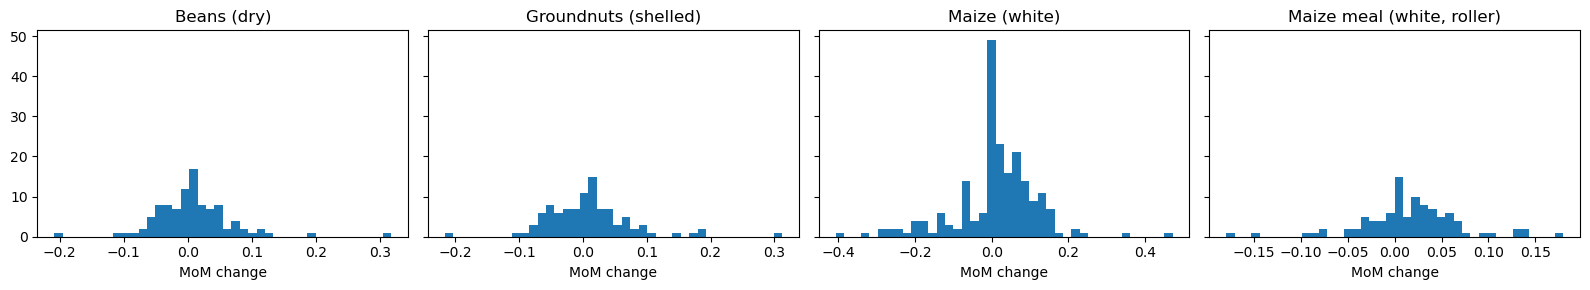

In [14]:
df["mom"] = df.groupby("commodity")["price"].pct_change()

stats = df.groupby("commodity")["mom"].agg(
    mean="mean", std="std", skew="skew", max="max", min="min"
)
print(stats.round(3))

fig, axes = plt.subplots(1, len(coms), figsize=(4 * len(coms), 3), sharey=True)
axes = np.atleast_1d(axes)
for ax, com in zip(axes, coms):
    ax.hist(df.loc[df["commodity"] == com, "mom"].dropna(), bins=40)
    ax.set_title(com)
    ax.set_xlabel("MoM change")
plt.tight_layout()
plt.show()

In [15]:
thresholds = [0.10, 0.15, 0.20, 0.25]
rows = []
for com in coms:
    m = df.loc[df["commodity"] == com, "mom"].dropna()
    r = {"commodity": com}
    for t in thresholds:
        r[f"> {int(t*100)}%"] = round((m > t).mean() * 100, 1)
    r["> mean+2sd"] = round((m > m.mean() + 2 * m.std()).mean() * 100, 1)
    rows.append(r)

pd.DataFrame(rows).set_index("commodity")   # values are % of months

,> 10%,> 15%,> 20%,> 25%,> mean+2sd
commodity,,,,,
Beans (dry),5.0,2.0,1.0,1.0,2.0
Groundnuts (shelled),6.1,5.1,1.0,1.0,5.1
Maize (white),15.3,4.3,2.4,1.0,1.4
"Maize meal (white, roller)",6.2,1.0,0.0,0.0,5.2


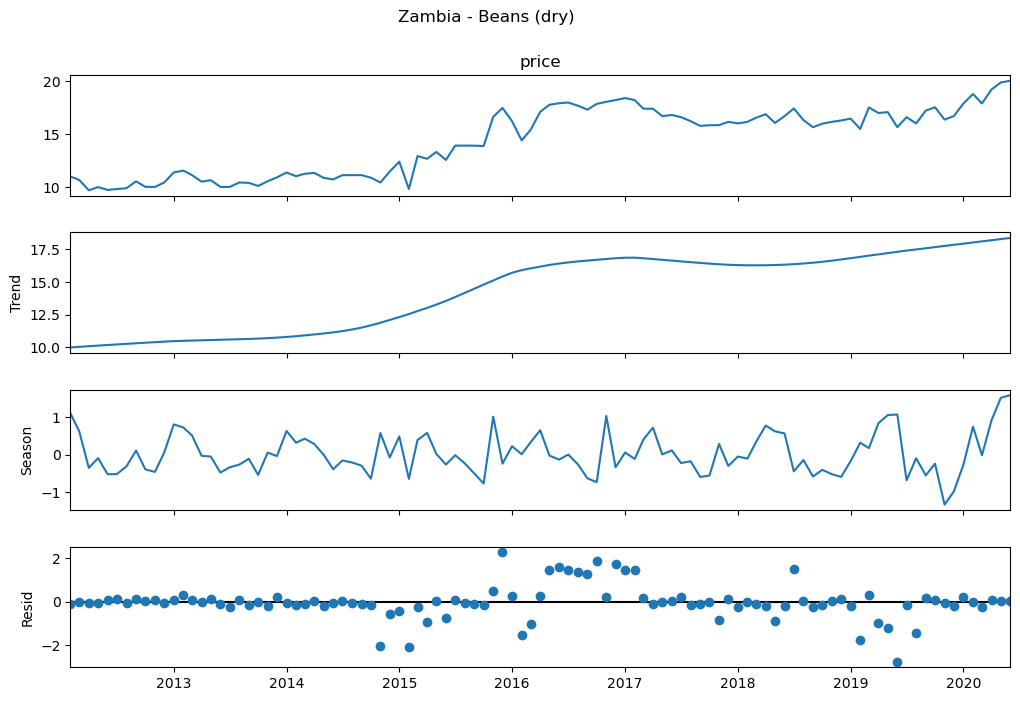

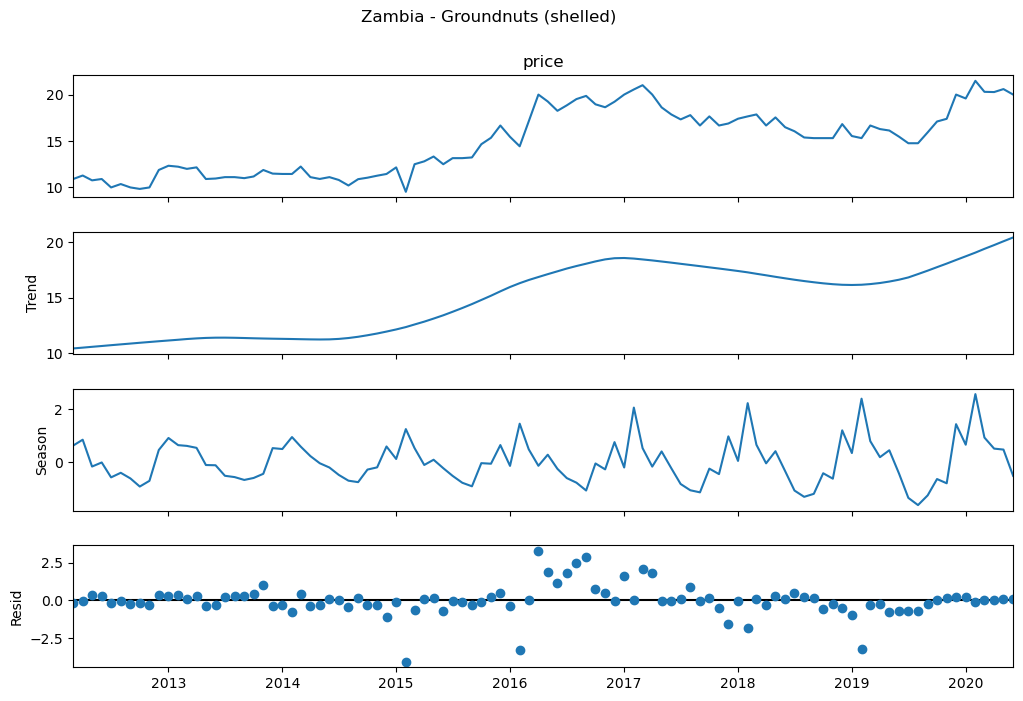

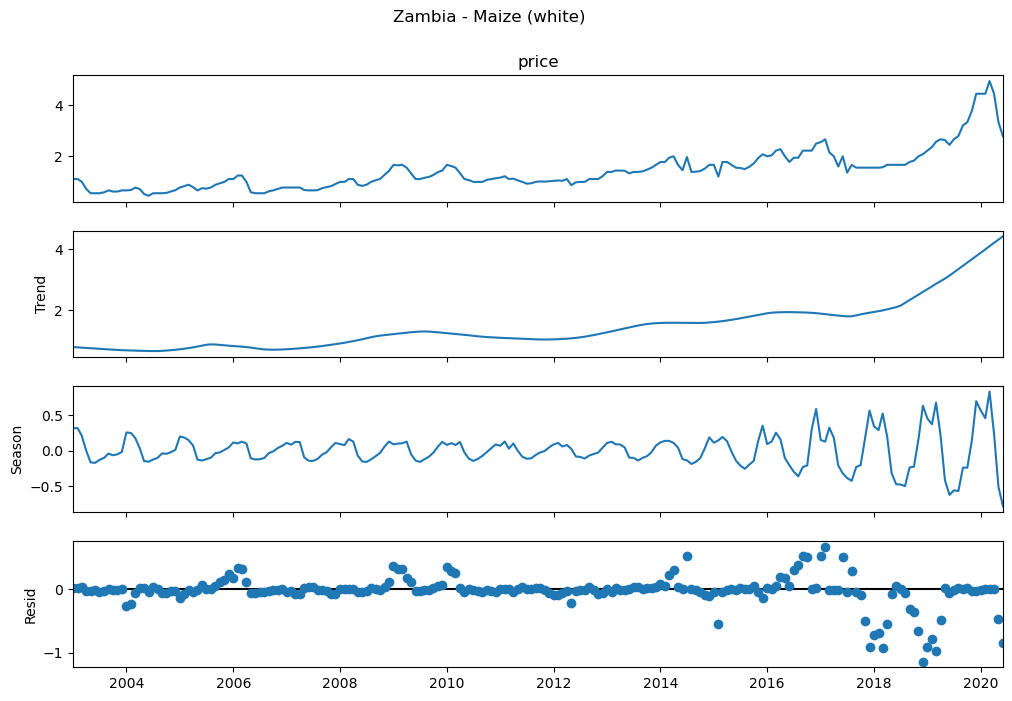

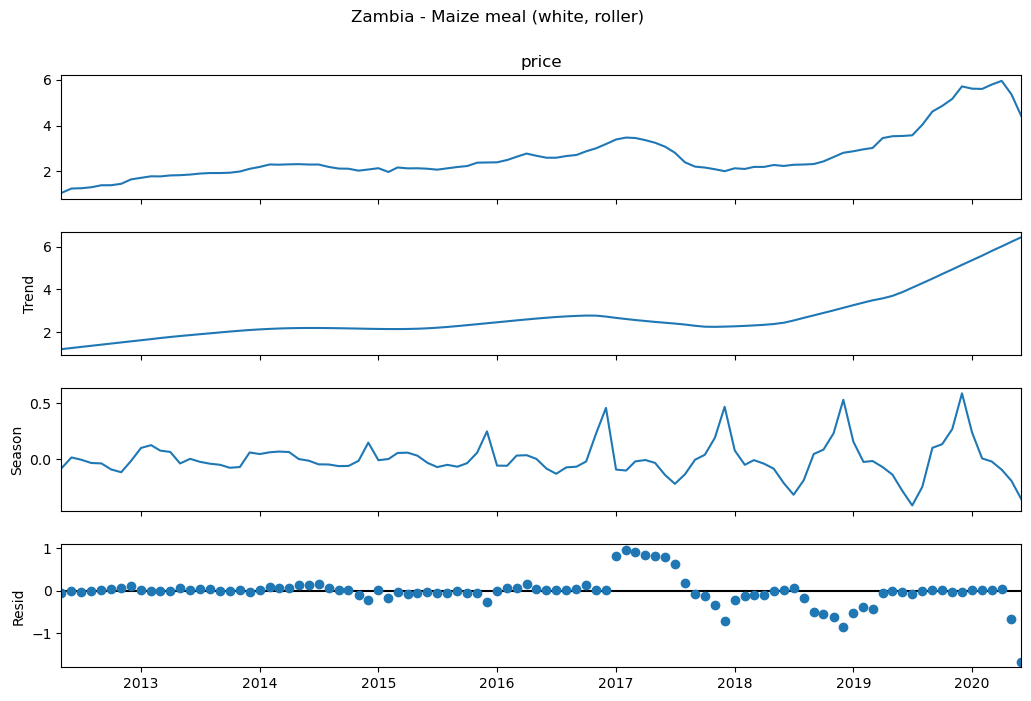

In [16]:
for com in coms:
    s = df[df["commodity"] == com].set_index("date")["price"]
    s.index.freq = "MS"
    res = STL(s, period=12, robust=True).fit()
    fig = res.plot()
    fig.set_size_inches(11, 7)
    fig.suptitle(f"{COUNTRY} - {com}", y=1.02)
    plt.show()

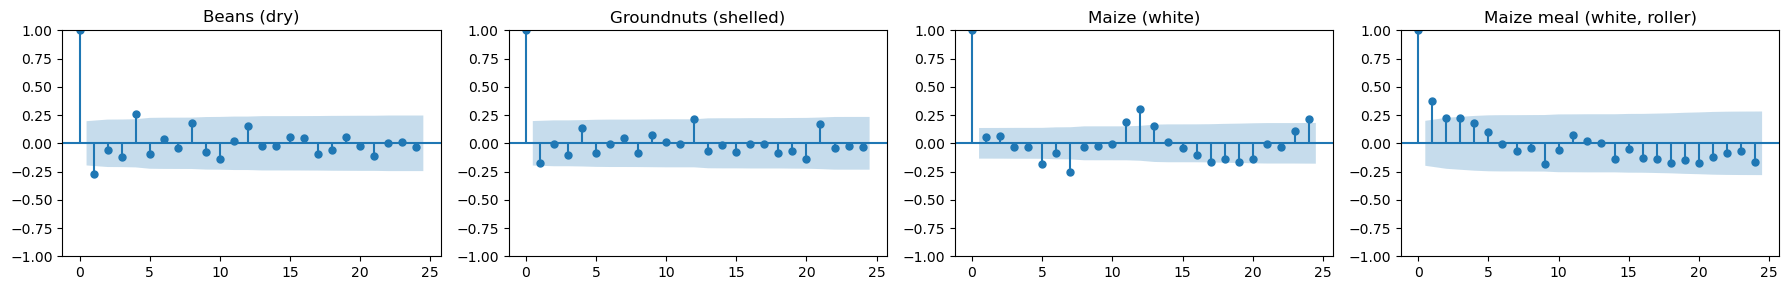

In [17]:
fig, axes = plt.subplots(1, len(coms), figsize=(4.5 * len(coms), 3))
axes = np.atleast_1d(axes)
for ax, com in zip(axes, coms):
    m = df.loc[df["commodity"] == com, "mom"].dropna()
    plot_acf(m, lags=24, ax=ax, title=com)
plt.tight_layout()
plt.show()